# TP5 — Partie B.1 : Bases de LangGraph

LangChain fournit des briques de haut niveau (`create_agent`) ; **LangGraph** est le framework *bas niveau* d'orchestration : on modélise explicitement l'application comme un **graphe d'états** :

| Concept | Rôle |
|---|---|
| **State** | structure de données partagée (TypedDict) : l'instantané courant de l'application |
| **Node** | fonction Python `state → mise à jour de l'état` |
| **Edge** | transition entre nœuds : fixe, **conditionnelle** (routage) ou en **boucle** |
| **Reducer** | règle de fusion d'un champ de l'état (ex. `add_messages` ajoute au lieu d'écraser) |
| **Checkpointer** | sauvegarde de l'état par `thread_id` → mémoire, reprise, human-in-the-loop |

Plan : 1) graphe simple · 2) branche conditionnelle · 3) boucle · 4) agent ReAct avec tools · 5) streaming · 6) mémoire · 7) human-in-the-loop · 8) système multi-agents (superviseur).

In [1]:
from typing import TypedDict, Literal, Sequence, Annotated
from IPython.display import Image, Markdown, display
from langgraph.graph import StateGraph, START, END
from langchain.messages import AnyMessage, HumanMessage, AIMessage, SystemMessage


def afficher_graphe(graph):
    """Affiche le graphe compilé (PNG via mermaid.ink, sinon code Mermaid)."""
    try:
        display(Image(graph.get_graph().draw_mermaid_png()))
    except Exception:
        print(graph.get_graph().draw_mermaid())

## 1. Graphe simple : State → Node → Edges

**1- État** : un `TypedDict` avec une liste de messages et un compteur.

In [2]:
class SimpleGraphState(TypedDict):
    messages: Sequence[AnyMessage]
    counter: int

**2- Nœud** : il lit l'état, ajoute un `AIMessage` (la requête inversée en majuscules) et met à jour le compteur.

In [3]:
def graph_node(state: SimpleGraphState) -> SimpleGraphState:
    """Reverse the string input"""
    query = state["messages"][-1].content
    reponse = AIMessage(content=f"Agent Response to query : [{query}], Output : {query.upper()[::-1]}")
    return {"messages": state["messages"] + [reponse], "counter": 10}

**3- Compilation** : `START → node → END`, puis **4- visualisation**.

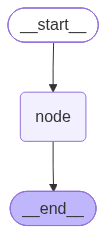

In [4]:
workflow = StateGraph(SimpleGraphState)
workflow.add_node("node", graph_node)
workflow.add_edge(START, "node")
workflow.add_edge("node", END)
graph = workflow.compile()
afficher_graphe(graph)

**5- Invocation** : le nœud reçoit l'état initial et renvoie l'état mis à jour.

In [5]:
resp = graph.invoke({"messages": [HumanMessage("My Name is Mohamed")]})
print("counter =", resp["counter"])
for message in resp["messages"]:
    message.pretty_print()

counter = 10
================================ Human Message =================================

My Name is Mohamed
================================== Ai Message ==================================

Agent Response to query : [My Name is Mohamed], Output : DEMAHOM SI EMAN YM


## 2. Branche conditionnelle (`add_conditional_edges`)

Un nœud d'analyse écrit une **décision** dans l'état ; une fonction de **routage** lit cette décision et choisit le chemin suivant.

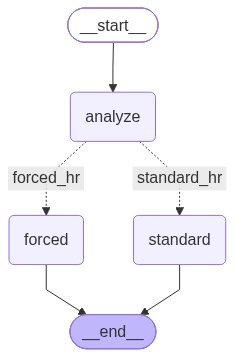

In [6]:
# 1) État partagé du workflow
class EmployeeState(TypedDict):
    name: str
    age: int
    salary: float
    decision: Literal["standard_hr", "forced_hr"]
    result: str


# 2) Nœud de vérification
def analyze_employee(state: EmployeeState) -> EmployeeState:
    if state["age"] <= 30 and state["salary"] <= 40000:
        state["decision"] = "standard_hr"
    else:
        state["decision"] = "forced_hr"
    return state


# 3) Chemin 1
def standard_hr_process(state: EmployeeState) -> EmployeeState:
    state["result"] = f"Demande de {state['name']} envoyée au traitement RH standard"
    return state


# 4) Chemin 2
def forced_hr_validation(state: EmployeeState) -> EmployeeState:
    state["result"] = f"Demande de {state['name']} envoyée à la validation RH forcée"
    return state


# 5) Fonction de routage conditionnel
def router(state: EmployeeState):
    return state["decision"]


wf = StateGraph(EmployeeState)
wf.add_node("analyze", analyze_employee)
wf.add_node("standard", standard_hr_process)
wf.add_node("forced", forced_hr_validation)
wf.add_edge(START, "analyze")
wf.add_conditional_edges("analyze", router, {"standard_hr": "standard", "forced_hr": "forced"})
wf.add_edge("standard", END)
wf.add_edge("forced", END)
graph = wf.compile()
afficher_graphe(graph)

In [7]:
print(graph.invoke({"name": "Mohamed", "age": 23, "salary": 20000}))
print(graph.invoke({"name": "Yassine", "age": 55, "salary": 65000}))

{'name': 'Mohamed', 'age': 23, 'salary': 20000, 'decision': 'standard_hr', 'result': 'Demande de Mohamed envoyée au traitement RH standard'}
{'name': 'Yassine', 'age': 55, 'salary': 65000, 'decision': 'forced_hr', 'result': 'Demande de Yassine envoyée à la validation RH forcée'}


## 3. Graphe avec boucle

Le dossier administratif est vérifié ; tant qu'il manque des documents, on **notifie** l'employé puis on **revient** à la vérification (arête `employee_notification → file_verification`).

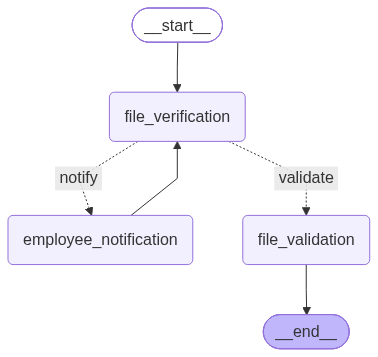

In [8]:
class AdministrativeFileState(TypedDict):
    name: str
    remaining_documents: int
    reminders: int
    status: Literal["incomplete", "complete", "validated"]


def verify_employee_file(state: AdministrativeFileState):
    state["status"] = "incomplete" if state["remaining_documents"] > 0 else "complete"
    print(f"Vérification du dossier de {state['name']} → statut : {state['status']}")
    return state


def notify_employee(state: AdministrativeFileState):
    state["reminders"] += 1
    if state["remaining_documents"] > 0:
        state["remaining_documents"] -= 1
    print(f"   Relance n°{state['reminders']} → documents restants : {state['remaining_documents']}")
    return state


def validate_file(state: AdministrativeFileState):
    state["status"] = "validated"
    print(f"✅ Dossier de {state['name']} validé")
    return state


def router(state: AdministrativeFileState) -> Literal["notify", "validate"]:
    return "notify" if state["status"] == "incomplete" else "validate"


workflow = StateGraph(AdministrativeFileState)
workflow.add_node("file_verification", verify_employee_file)
workflow.add_node("employee_notification", notify_employee)
workflow.add_node("file_validation", validate_file)
workflow.set_entry_point("file_verification")
workflow.add_conditional_edges("file_verification", router,
                               {"notify": "employee_notification", "validate": "file_validation"})
workflow.add_edge("employee_notification", "file_verification")
workflow.add_edge("file_validation", END)
graph = workflow.compile()
afficher_graphe(graph)

In [9]:
resp = graph.invoke({"name": "Mohamed", "remaining_documents": 4, "reminders": 0})
print(resp)

Vérification du dossier de Mohamed → statut : incomplete
   Relance n°1 → documents restants : 3
Vérification du dossier de Mohamed → statut : incomplete
   Relance n°2 → documents restants : 2
Vérification du dossier de Mohamed → statut : incomplete
   Relance n°3 → documents restants : 1
Vérification du dossier de Mohamed → statut : incomplete
   Relance n°4 → documents restants : 0
Vérification du dossier de Mohamed → statut : complete
✅ Dossier de Mohamed validé
{'name': 'Mohamed', 'remaining_documents': 0, 'reminders': 4, 'status': 'validated'}


## 4. Agent ReAct avec LangGraph

Contrairement à `create_agent` (Partie A), on construit ici l'agent **à la main** :
- l'état contient les messages, avec le **reducer** `add_messages` (chaque nœud *ajoute* ses messages) ;
- nœud `assistant` = le LLM lié aux tools (`bind_tools`) → **MIND** ;
- nœud `tools` = `ToolNode` qui exécute les appels → **BODY** ;
- arête conditionnelle `should_continue` : s'il y a des `tool_calls` → `tools`, sinon → `END` ;
- arête `tools → assistant` : la **boucle ReAct** (Raisonnement → Action → Observation).

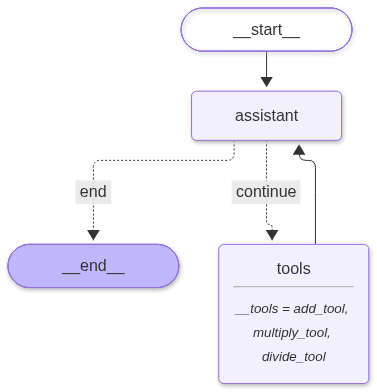

In [10]:
from langchain_core.messages import BaseMessage
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langchain.tools import tool
from langchain_ollama import ChatOllama

# qwen3-vl:8b (Ollama, local) ; reasoning=False : le raisonnement interne n'est pas renvoyé
llm = ChatOllama(model="qwen3-vl:8b", temperature=0, reasoning=False, num_ctx=16384)


class SimpleAgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]


@tool
def add_tool(a: float, b: float) -> float:
    """Add 2 numbers a and b"""
    print(f"   add_tool({a}, {b})")
    return a + b


@tool
def multiply_tool(a: float, b: float) -> float:
    """Multiply 2 numbers a and b"""
    print(f"   multiply_tool({a}, {b})")
    return a * b


@tool
def divide_tool(a: float, b: float) -> float:
    """Divide 2 numbers a by b"""
    print(f"   divide_tool({a}, {b})")
    return a / b


tools = [add_tool, multiply_tool, divide_tool]
llm_with_tools = llm.bind_tools(tools)


def assistant(state: SimpleAgentState):
    system = SystemMessage("Answer the user question using the provided tools for every computation. "
                           "Call the tools one step at a time.")
    return {"messages": [llm_with_tools.invoke([system] + list(state["messages"]))]}


def should_continue(state: SimpleAgentState):
    return "continue" if state["messages"][-1].tool_calls else "end"


workflow = StateGraph(SimpleAgentState)
workflow.add_node("assistant", assistant)
workflow.add_node("tools", ToolNode(tools))
workflow.add_edge(START, "assistant")
workflow.add_conditional_edges("assistant", should_continue, {"continue": "tools", "end": END})
workflow.add_edge("tools", "assistant")
graph = workflow.compile()
afficher_graphe(graph)

In [11]:
resp = graph.invoke({"messages": [HumanMessage(
    "Compute this expression : Add 6 to 7 then divide by 2 and multiply by 5. Puis donne moi un proverbe")]})
print(resp["messages"][-1].content)

   divide_tool(13.0, 2.0)   add_tool(6.0, 7.0)
   multiply_tool(6.5, 5.0)



The result of the computation is **32.5**.

**Proverbe :**  
*« Qui ne risque rien n'a rien. »*  
(Translation: *He who does not risk nothing has nothing.*)


## 5. Streaming

`graph.stream(..., stream_mode="values")` renvoie l'état complet **après chaque nœud** : on suit pas à pas le cycle ReAct.

In [12]:
stream = graph.stream({"messages": [HumanMessage("Add 5 to 80 then multiply by 23")]}, stream_mode="values")
for item in stream:
    message = item["messages"][-1]
    if isinstance(message, BaseMessage):
        message.pretty_print()

================================ Human Message =================================

Add 5 to 80 then multiply by 23


================================== Ai Message ==================================
Tool Calls:
  add_tool (7cf62b85-33aa-4f16-877a-3da34f6ce3b6)
 Call ID: 7cf62b85-33aa-4f16-877a-3da34f6ce3b6
  Args:
    a: 80
    b: 5
   add_tool(80.0, 5.0)
================================= Tool Message =================================
Name: add_tool

85.0


================================== Ai Message ==================================
Tool Calls:
  multiply_tool (a55dfe4f-a601-4a15-a4c0-87656c1a06e0)
 Call ID: a55dfe4f-a601-4a15-a4c0-87656c1a06e0
  Args:
    a: 85
    b: 23
   multiply_tool(85.0, 23.0)
================================= Tool Message =================================
Name: multiply_tool

1955.0


================================== Ai Message ==================================

The result of adding 5 to 80 and then multiplying by 23 is **1955.0**.


## 6. Mémoire (checkpointer)

On recompile **le même workflow** avec un `InMemorySaver` : l'état est sauvegardé par `thread_id`.

In [13]:
from langgraph.checkpoint.memory import InMemorySaver

graph_with_memory = workflow.compile(checkpointer=InMemorySaver())
config = {"configurable": {"thread_id": "1"}}

result = graph_with_memory.invoke({"messages": [HumanMessage("Mon nom est Mohamed")]}, config=config)
print(result["messages"][-1].content)
result = graph_with_memory.invoke({"messages": [HumanMessage("C'est quoi mon nom ?")]}, config=config)
print(result["messages"][-1].content)

Bonjour Mohamed ! 😊 Je suis ravi de faire votre connaissance. Si vous avez besoin d'aide pour des calculs mathématiques (addition, multiplication, division), n'hésitez pas à me demander !


Votre nom est Mohamed. 😊 Je me souviens de votre présentation précédente ! N'hésitez pas à me demander de l'aide pour des calculs mathématiques si vous le souhaitez.


In [14]:
# L'état sauvegardé pour le thread 1
for m in graph_with_memory.get_state(config).values["messages"]:
    print(f"{m.type:>6} : {m.content}")

 human : Mon nom est Mohamed
    ai : Bonjour Mohamed ! 😊 Je suis ravi de faire votre connaissance. Si vous avez besoin d'aide pour des calculs mathématiques (addition, multiplication, division), n'hésitez pas à me demander !
 human : C'est quoi mon nom ?
    ai : Votre nom est Mohamed. 😊 Je me souviens de votre présentation précédente ! N'hésitez pas à me demander de l'aide pour des calculs mathématiques si vous le souhaitez.


## 7. Human In The Loop (`interrupt` / `Command(resume=...)`)

Un nœud `human_review` appelle `interrupt(payload)` : le graphe **se met en pause** (l'état est sauvegardé par le checkpointer) et renvoie `__interrupt__`.
On reprend avec `graph.invoke(Command(resume=...), config)` : la valeur passée devient le retour de `interrupt()`.
Ici, un LLM rédige un email ; l'humain le refuse avec un commentaire, le LLM le réécrit, puis l'humain l'approuve.

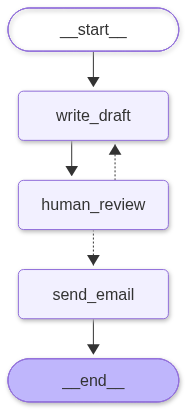

In [15]:
from langgraph.types import interrupt, Command


class EmailState(TypedDict, total=False):
    recipient: str
    subject: str
    intent: str
    draft: str
    approved: bool
    feedback: str


def write_draft(state: EmailState):
    prompt = f"""Tu es un assistant qui rédige des emails professionnels en français.
Destinataire: {state['recipient']}
Sujet: {state['subject']}
Objectif: {state['intent']}
Brouillon précédent: {state.get('draft') or '(aucun)'}
Commentaire humain: {state.get('feedback') or 'Aucun commentaire. Rédige un premier brouillon.'}
Instructions: rédige un email clair, poli et concis (5 lignes maximum). Si un commentaire humain est fourni,
réécris le brouillon en en tenant compte. Retourne uniquement le corps de l'email."""
    return {"draft": llm.invoke(prompt).content}


def human_review(state: EmailState):
    decision = interrupt({"draft": state["draft"], "message": "Valider ce brouillon ? (approved / feedback)"})
    return {"approved": decision["approved"], "feedback": decision.get("feedback", "")}


def route_after_review(state: EmailState) -> Literal["send_email", "write_draft"]:
    return "send_email" if state["approved"] else "write_draft"


def send_email(state: EmailState):
    print(f"📧 Email envoyé à {state['recipient']}")
    return {}


builder = StateGraph(EmailState)
builder.add_node("write_draft", write_draft)
builder.add_node("human_review", human_review)
builder.add_node("send_email", send_email)
builder.add_edge(START, "write_draft")
builder.add_edge("write_draft", "human_review")
builder.add_conditional_edges("human_review", route_after_review)
builder.add_edge("send_email", END)
graph = builder.compile(checkpointer=InMemorySaver())
afficher_graphe(graph)

In [16]:
config = {"configurable": {"thread_id": "email-demo-1"}}
result = graph.invoke({
    "recipient": "client@example.com",
    "subject": "Proposition de rendez-vous",
    "intent": "Proposer un rendez-vous la semaine prochaine afin de présenter notre offre.",
}, config=config)

# Décisions humaines simulées (en interactif : input())
decisions = [
    {"approved": False, "feedback": "Propose deux créneaux précis : mardi 10h ou jeudi 15h."},
    {"approved": True},
]
for decision in decisions:
    payload = result["__interrupt__"][0].value
    print("--- BROUILLON À VALIDER ---")
    display(Markdown(payload["draft"]))
    print("Décision humaine :", decision)
    result = graph.invoke(Command(resume=decision), config=config)

print("Terminé :", "__interrupt__" not in result, "| approuvé :", result["approved"])

--- BROUILLON À VALIDER ---


Bonjour,  
Je vous propose un rendez-vous la semaine prochaine afin de vous présenter notre offre en détail.  
Pourriez-vous me confirmer votre disponibilité ou suggérer une date qui vous convient ?  
Je reste à votre disposition pour ajuster le créneau selon vos besoins.  
Cordialement,

Décision humaine : {'approved': False, 'feedback': 'Propose deux créneaux précis : mardi 10h ou jeudi 15h.'}


--- BROUILLON À VALIDER ---


Bonjour,  
Je vous propose deux créneaux : mardi à 10h ou jeudi à 15h.  
Pourriez-vous confirmer votre disponibilité ?  
Je reste à votre disposition pour ajuster selon vos besoins.  
Cordialement,

Décision humaine : {'approved': True}
📧 Email envoyé à client@example.com
Terminé : True | approuvé : True


## 8. Système multi-agents (superviseur)

Un **superviseur** analyse la demande et choisit l'agent spécialisé grâce à une **sortie structurée** (`with_structured_output`) : c'est le même schéma que l'orchestrateur du travail de synthèse (Partie D).

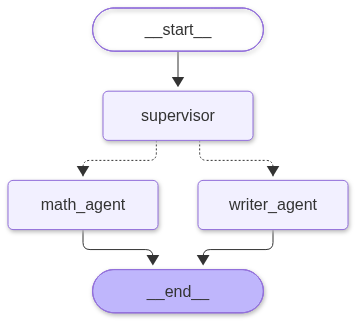

In [17]:
class MASState(TypedDict):
    messages: Annotated[list, add_messages]
    next: str


class Router(TypedDict):
    next: Literal["math_agent", "writer_agent"]


router_llm = llm.with_structured_output(Router)


def supervisor_node(state: MASState):
    decision = router_llm.invoke([
        SystemMessage("Tu es un superviseur dans un système multi-agents. "
                      "Choisis 'math_agent' pour un calcul, 'writer_agent' pour une tâche de rédaction."),
        *state["messages"],
    ])
    print(f"🧭 superviseur → {decision['next']}")
    return {"next": decision["next"]}


def math_agent(state: MASState):
    r = llm.invoke([SystemMessage("Tu es un agent mathématique. Donne le résultat avec une courte justification."),
                    *state["messages"]])
    return {"messages": [AIMessage(r.content, name="math_agent")]}


def writer_agent(state: MASState):
    r = llm.invoke([SystemMessage("Tu es un agent de rédaction. Rédige un texte court et professionnel en français."),
                    *state["messages"]])
    return {"messages": [AIMessage(r.content, name="writer_agent")]}


mas = StateGraph(MASState)
mas.add_node("supervisor", supervisor_node)
mas.add_node("math_agent", math_agent)
mas.add_node("writer_agent", writer_agent)
mas.add_edge(START, "supervisor")
mas.add_conditional_edges("supervisor", lambda s: s["next"], ["math_agent", "writer_agent"])
mas.add_edge("math_agent", END)
mas.add_edge("writer_agent", END)
graph = mas.compile()
afficher_graphe(graph)

In [18]:
for question in ["Calcule 18 * 27", "Rédige un email pour demander un rendez-vous"]:
    result = graph.invoke({"messages": [HumanMessage(question)]})
    print(f"Q : {question}\nR ({result['messages'][-1].name}) : {result['messages'][-1].content}\n")

🧭 superviseur → math_agent


Q : Calcule 18 * 27
R (math_agent) : 18 * 27 = 486  
**Justification** : Utilisation de la distributivité : $18 \times (20 + 7) = 18 \times 20 + 18 \times 7 = 360 + 126 = 486$.



🧭 superviseur → writer_agent


Q : Rédige un email pour demander un rendez-vous
R (writer_agent) : **Objet** : Demande de rendez-vous  

Bonjour [Nom],  

Je vous propose un rendez-vous pour discuter d’un sujet professionnel. Je suis disponible les [dates] à [heures] et reste à votre disposition pour ajuster le créneau selon vos disponibilités.  

Merci de votre attention, et n’hésitez pas à me faire savoir si vous souhaitez préciser votre disponibilité.  

Cordialement,  
[Votre nom]  
[Votre poste]  
[Coordonnées]

